# Adversarial Search: Playing Connect 4

Student Name: Truong Chi Long - 3123410198

I have used the following AI tools: Gemini 4 Argon - Copilot

I understand that my submission needs to be my own work: T.C.L

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

In [2]:
import math

def estimate_connect4_complexity(rows=6, cols=7):
    total_cells = rows * cols
    naive_states = 3 ** total_cells
    # Mỗi cột có chiều cao R chỉ có thể chứa từ 0 đến R quân xếp từ đáy lên:
    # Số cấu hình hợp lệ theo trọng lực của 1 cột là sum_{k=0}^R 2^k = 2^(R+1) - 1
    col_configs = (2 ** (rows + 1)) - 1
    gravity_states = col_configs ** cols
    game_tree_upper = cols ** total_cells
    return naive_states, gravity_states, game_tree_upper

for r, c in [(4, 4), (4, 5), (6, 7)]:
    naive_s, grav_s, tree_s = estimate_connect4_complexity(r, c)
    print(f"Bàn {r}x{c}: Cận thô = {naive_s:.2e} | Cận trọng lực = {grav_s:.2e} | Cây trò chơi (b^m) = {tree_s:.2e}")

Bàn 4x4: Cận thô = 4.30e+07 | Cận trọng lực = 9.24e+05 | Cây trò chơi (b^m) = 4.29e+09
Bàn 4x5: Cận thô = 3.49e+09 | Cận trọng lực = 2.86e+07 | Cây trò chơi (b^m) = 9.54e+13
Bàn 6x7: Cận thô = 1.09e+20 | Cận trọng lực = 5.33e+14 | Cây trò chơi (b^m) = 3.12e+35


How big is the state space? Give an estimate and explain it.

`<Your answer goes here>`

How big is the game tree that minimax search will go through? Give an estimate and explain it.

`<Your answer goes here>`

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

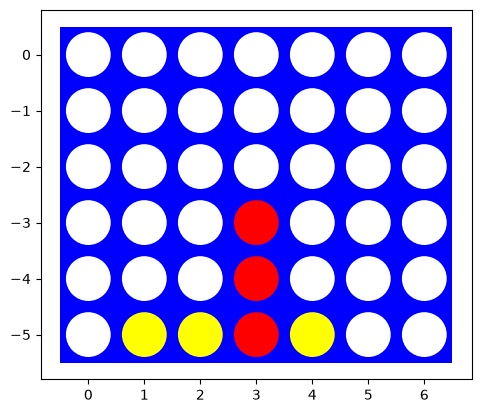

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [ ]:
import numpy as np
import time

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0, dtype=int)

def actions(state):
    """Trả về danh sách các cột còn ô trống ở hàng trên cùng (row = 0)."""
    return np.where(state[0, :] == 0)[0].tolist()

def result(state, player, action):
    """Thả đĩa của player (1 hoặc -1) vào cột action."""
    if state[0, action] != 0:
        raise ValueError(f"Cột {action} đã đầy!")
    new_state = state.copy()
    # Tìm hàng trống thấp nhất (chỉ số hàng lớn nhất có giá trị 0)
    empty_rows = np.where(new_state[:, action] == 0)[0]
    lowest_row = empty_rows[-1]
    new_state[lowest_row, action] = player
    return new_state

def check_winner(state, connect_k=4):
    """Kiểm tra người thắng trên bàn cờ R x C với điều kiện nối connect_k quân."""
    rows, cols = state.shape
    # 1. Kiểm tra hàng ngang
    for r in range(rows):
        for c in range(cols - connect_k + 1):
            window = state[r, c:c + connect_k]
            if abs(np.sum(window)) == connect_k and len(set(window)) == 1:
                return int(window[0])
    # 2. Kiểm tra cột dọc
    for r in range(rows - connect_k + 1):
        for c in range(cols):
            window = state[r:r + connect_k, c]
            if abs(np.sum(window)) == connect_k and len(set(window)) == 1:
                return int(window[0])
    # 3. Kiểm tra đường chéo chính (\) và đường chéo phụ (/)
    for r in range(rows - connect_k + 1):
        for c in range(cols - connect_k + 1):
            diag1 = [state[r + i, c + i] for i in range(connect_k)]
            if abs(sum(diag1)) == connect_k and len(set(diag1)) == 1:
                return int(diag1[0])
            diag2 = [state[r + connect_k - 1 - i, c + i] for i in range(connect_k)]
            if abs(sum(diag2)) == connect_k and len(set(diag2)) == 1:
                return int(diag2[0])
    return 0

def terminal(state):
    """Kiểm tra trạng thái kết thúc."""
    if check_winner(state) != 0:
        return True
    return len(actions(state)) == 0

def utility(state, player=1):
    """Trả về lợi ích (+1, -1, 0) cho trạng thái kết thúc, hoặc None nếu chưa kết thúc."""
    winner = check_winner(state)
    if winner != 0:
        return 1 if winner == player else -1
    if len(actions(state)) == 0:
        return 0
    return None


Random vs Random (1000 ván, bàn 6x7): {1: 532, -1: 468, 0: 0} | Thời gian: 2.17s
Random vs Random (1000 ván, bàn 4x4): {1: 271, -1: 226, 0: 503} | Thời gian: 0.38s


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player=1):
    """Tác tử chọn ngẫu nhiên một cột hợp lệ."""
    return int(np.random.choice(actions(board)))

def play_connect4(agent1, agent2, N=1000, shape=(6, 7)):
    """Cho hai tác tử đấu với nhau N ván. agent1 cầm quân 1 (Đỏ) đi trước."""
    results = {1: 0, -1: 0, 0: 0}
    for _ in range(N):
        board = empty_board(shape)
        current_player = 1
        while True:
            agent = agent1 if current_player == 1 else agent2
            move = agent(board, player=current_player)
            board = result(board, current_player, move)
            u = utility(board, player=1)
            if u is not None:
                results[u] += 1
                break
            current_player = -current_player
    return results

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
np.random.seed(42)
t0 = time.perf_counter()
res_6x7 = play_connect4(random_player, random_player, N=1000, shape=(6, 7))
t_6x7 = time.perf_counter() - t0

t0 = time.perf_counter()
res_4x4 = play_connect4(random_player, random_player, N=1000, shape=(4, 4))
t_4x4 = time.perf_counter() - t0

print(f"Random vs Random (1000 ván, bàn 6x7): {res_6x7} | Thời gian: {t_6x7:.2f}s")
print(f"Random vs Random (1000 ván, bàn 4x4): {res_4x4} | Thời gian: {t_4x4:.2f}s")

Random vs Random (1000 ván, bàn 6x7): {1: 532, -1: 468, 0: 0} | Thời gian: 2.08s
Random vs Random (1000 ván, bàn 4x4): {1: 271, -1: 226, 0: 503} | Thời gian: 0.37s


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [ ]:
import math

class AlphaBetaAgent:
    def __init__(self, use_move_ordering=False, use_opening_book=False):
        self.use_move_ordering = use_move_ordering
        self.use_opening_book = use_opening_book
        self.node_count = 0
        self.transposition_table = {}

    def ordered_actions(self, state):
        acts = actions(state)
        if not self.use_move_ordering:
            return acts
        center = (state.shape[1] - 1) / 2.0
        return sorted(acts, key=lambda c: abs(c - center))

    def search(self, board, player=1):
        self.node_count = 0
        self.transposition_table.clear()
        # Opening book cho bàn cờ rỗng: đánh ngay vào cột trung tâm
        if self.use_opening_book and np.all(board == 0):
            return {"move": board.shape[1] // 2, "value": 0, "nodes": 1}
        val, move = self._max_value(board, player, -math.inf, math.inf)
        return {"move": move, "value": val, "nodes": self.node_count}

    def _max_value(self, state, player, alpha, beta):
        self.node_count += 1
        u = utility(state, player)
        if u is not None:
            return u, None

        v, best_move = -math.inf, None
        for a in self.ordered_actions(state):
            v2, _ = self._min_value(result(state, player, a), player, alpha, beta)
            if v2 > v:
                v, best_move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_move
        return v, best_move

    def _min_value(self, state, player, alpha, beta):
        self.node_count += 1
        u = utility(state, player)
        if u is not None:
            return u, None

        v, best_move = math.inf, None
        for a in self.ordered_actions(state):
            v2, _ = self._max_value(result(state, -player, a), player, alpha, beta)
            if v2 < v:
                v, best_move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_move
        return v, best_move

    def __call__(self, board, player=1):
        return self.search(board, player)["move"]

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [ ]:
# Thiết lập 5 bàn cờ kiểm thử 4x4 cho người chơi Đỏ (player = 1)
# Test 1: Đỏ có 3 quân hàng ngang đáy (cột 0, 1, 2), cần đánh cột 3 để thắng ngay
b1 = np.array([[ 0,  0,  0,  0],
               [ 0,  0,  0,  0],
               [-1, -1,  0,  0],
               [ 1,  1,  1, -1]]) # cột 2 rỗng ở hàng 2, hoặc b1 dưới đây:
b1 = np.array([[ 0,  0,  0,  0],
               [ 0,  0,  0,  0],
               [-1, -1, -1,  0],
               [ 1,  1,  1,  0]])

# Test 2: Đỏ có 3 quân dọc ở cột 1, cần đánh cột 1 để thắng ngay
b2 = np.array([[ 0,  0,  0,  0],
               [ 0,  1,  0,  0],
               [-1,  1, -1,  0],
               [-1,  1, -1,  1]])

# Test 3: Vàng (-1) sắp thắng ở cột 2 (đã có 3 quân dọc), Đỏ buộc phải chặn ở cột 2
b3 = np.array([[ 0,  0,  0,  0],
               [ 0,  0, -1,  0],
               [ 1,  1, -1,  0],
               [ 1, -1, -1,  1]])

# Test 4: Đỏ thắng theo đường chéo chính nếu thả vào cột 0 (ô (0,0))
b4 = np.array([[ 0,  1, -1,  1],
               [ 1,  1, -1, -1],
               [-1, -1,  1,  1],
               [ 1, -1, -1,  1]])

# Test 5: Thế cờ giằng co giữa trận (6 quân đã đánh), tìm nước đi tối ưu đảm bảo thắng/hòa
b5 = np.array([[ 0,  0,  0,  0],
               [ 0,  0,  0,  0],
               [ 0,  1, -1,  0],
               [-1,  1, -1,  1]])

ab_basic = AlphaBetaAgent(use_move_ordering=False)
ab_ordered = AlphaBetaAgent(use_move_ordering=True)

for idx, tb in enumerate([b1, b2, b3, b4, b5], 1):
    t0 = time.perf_counter()
    r_basic = ab_basic.search(tb, player=1)
    t_basic = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    r_ord = ab_ordered.search(tb, player=1)
    t_ord = (time.perf_counter() - t0) * 1000
    print(f"Test {idx}: Move={r_ord['move']}, Value={r_ord['value']} | "
          f"Không Ordering: {r_basic['nodes']} nút ({t_basic:.2f}ms) | "
          f"Có Ordering: {r_ord['nodes']} nút ({t_ord:.2f}ms)")

Test 1: Move=3, Value=1 | Không Ordering: 2670 nút (47.31ms) | Có Ordering: 2988 nút (49.13ms)
Test 2: Move=1, Value=1 | Không Ordering: 136 nút (2.20ms) | Có Ordering: 90 nút (1.60ms)
Test 3: Move=2, Value=0 | Không Ordering: 293 nút (4.89ms) | Có Ordering: 227 nút (4.01ms)
Test 4: Move=0, Value=1 | Không Ordering: 2 nút (0.04ms) | Có Ordering: 2 nút (0.03ms)
Test 5: Move=1, Value=0 | Không Ordering: 2287 nút (38.26ms) | Có Ordering: 1027 nút (17.89ms)


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [17]:
def eval_window(window, player):
    score = 0
    opp = -player
    p_count = np.sum(window == player)
    o_count = np.sum(window == opp)
    if p_count > 0 and o_count > 0:
        return 0  # Cửa sổ đã bị chặn bởi cả hai bên
    if p_count == 3:
        score += 10
    elif p_count == 2:
        score += 3
    elif o_count == 3:
        score -= 10
    elif o_count == 2:
        score -= 3
    return score

def eval_fun(state, player=1, connect_k=4):
    """Hàm đánh giá heuristic trả về (score, is_terminal) với score thuộc [-1, 1]."""
    u = utility(state, player)
    if u is not None:
        return float(u), True

    rows, cols = state.shape
    score = 0.0
    # Thưởng kiểm soát cột trung tâm
    center_col = state[:, cols // 2]
    score += 2.0 * (np.sum(center_col == player) - np.sum(center_col == -player))

    # Quét ngang, dọc, chéo
    for r in range(rows):
        for c in range(cols - connect_k + 1):
            score += eval_window(state[r, c:c + connect_k], player)
    for r in range(rows - connect_k + 1):
        for c in range(cols):
            score += eval_window(state[r:r + connect_k, c], player)
    for r in range(rows - connect_k + 1):
        for c in range(cols - connect_k + 1):
            w1 = np.array([state[r + i, c + i] for i in range(connect_k)])
            w2 = np.array([state[r + connect_k - 1 - i, c + i] for i in range(connect_k)])
            score += eval_window(w1, player) + eval_window(w2, player)

    normalized_score = np.clip(score / 150.0, -0.99, 0.99)
    return float(normalized_score), False

class HeuristicAlphaBetaAgent:
    def __init__(self, cutoff=4, use_move_ordering=True):
        self.cutoff = cutoff
        self.use_move_ordering = use_move_ordering
        self.node_count = 0

    def ordered_actions(self, state):
        acts = actions(state)
        if not self.use_move_ordering:
            return acts
        center = (state.shape[1] - 1) / 2.0
        return sorted(acts, key=lambda c: abs(c - center))

    def search(self, board, player=1):
        self.node_count = 0
        val, move = self._max_ab(board, player, -math.inf, math.inf, 0)
        return {"move": move, "value": round(val, 4), "nodes": self.node_count}

    def _max_ab(self, state, player, alpha, beta, depth):
        self.node_count += 1
        v_eval, is_term = eval_fun(state, player)
        if is_term or (self.cutoff is not None and depth >= self.cutoff):
            return v_eval, None

        v, best_move = -math.inf, None
        for a in self.ordered_actions(state):
            v2, _ = self._min_ab(result(state, player, a), player, alpha, beta, depth + 1)
            if v2 > v:
                v, best_move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, best_move
        return v, best_move

    def _min_ab(self, state, player, alpha, beta, depth):
        self.node_count += 1
        v_eval, is_term = eval_fun(state, player)
        if is_term or (self.cutoff is not None and depth >= self.cutoff):
            return v_eval, None

        v, best_move = math.inf, None
        for a in self.ordered_actions(state):
            v2, _ = self._max_ab(result(state, -player, a), player, alpha, beta, depth + 1)
            if v2 < v:
                v, best_move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, best_move
        return v, best_move

    def __call__(self, board, player=1):
        return self.search(board, player)["move"]

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

Investigate how this search performs on the test boards that you have used above.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

`<Your Answer goes here>`

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [18]:
def playout_connect4(state, action, player=1):
    """Mô phỏng ngẫu nhiên 1 ván cờ từ hành động 'action' của 'player' tới khi kết thúc."""
    curr_state = result(state, player, action)
    curr_player = -player
    while True:
        u = utility(curr_state, player)
        if u is not None:
            return u
        a = int(np.random.choice(actions(curr_state)))
        curr_state = result(curr_state, curr_player, a)
        curr_player = -curr_player

def pmcs_connect4(board, N=200, player=1):
    """Pure Monte Carlo Search chia đều N playouts cho các hành động hợp lệ."""
    acts = actions(board)
    n_per_action = max(1, N // len(acts))
    scores = {}
    for a in acts:
         scores[a] = np.mean([playout_connect4(board, a, player) for _ in range(n_per_action)])
    best_action = max(scores, key=scores.get)
    return best_action, scores

class PMCSAgent:
    def __init__(self, N=200):
        self.N = N
    def __call__(self, board, player=1):
        move, _ = pmcs_connect4(board, N=self.N, player=player)
        return move